In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become erro

In [18]:
seu_ile_lp_filt  <-  readRDS("data/cdn/seu5p_ile_lp_filt.rds")

In [5]:
seu_ile_lp_filt

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [22]:
seu_ile_lp_filt$barcode  <- colnames(seu_ile_lp_filt)

In [23]:
subset_seu_ile_lp  <- subset(seu_ile_lp_filt, barcode %in% sample(colnames(seu_ile_lp_filt), size = 300000))

In [24]:
subset_seu_ile_lp$participant_id

AAACCTGAGAGCCTAG-1_1193610_1_1_1 AAACCTGCACATTAGC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACCTGGTATGAATG-1_1193610_1_1_1 AAACCTGGTTTGACAC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACCTGTCATAGCAC-1_1193610_1_1_1 AAACCTGTCCTCCTAG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACCTGTCGCGATCG-1_1193610_1_1_1 AAACCTGTCTGTTGAG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACGGGAGCGTTTAC-1_1193610_1_1_1 AAACGGGAGTACGTAA-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACGGGAGTGCCATT-1_1193610_1_1_1 AAACGGGAGTGTACGG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAACGGGCAGGTGCCT-1_1193610_1_1_1 AAACGGGGTAAGAGAG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGAGACGCAAC-1_1193610_1_1_1 AAAGATGAGATGCCTT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGAGCATGGCA-1_1193610_1_1_1 AAAGATGAGTAGTGCG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGAGTGGAGTC-1_1193610_1_1_1 AAAGATGGTCTACCTC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGGTGCGGTAA-1_1193610_1_1_1 AAAGATGGTGTCAATC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGGTTCCACAA-1_1193610_1_1_1 AAAGATGTCAATAAGG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGATGTCACCTCGT-1_1193610_1_1_1 AAAGATGTCAGGTAAA-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGCAAAGAATAGGG-1_1193610_1_1_1 AAAGCAAAGCCCAATT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGCAAGTTGGTAAA-1_1193610_1_1_1 AAAGCAATCACAGGCC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGCAATCCATGCTC-1_1193610_1_1_1 AAAGTAGAGAGGTTGC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGCACTGTCGG-1_1193610_1_1_1 AAAGTAGCAGACGCTC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGCAGCGTCCA-1_1193610_1_1_1 AAAGTAGCATCTATGG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGCATCTCCCA-1_1193610_1_1_1 AAAGTAGGTAACGCGA-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGGTCAGAGGT-1_1193610_1_1_1 AAAGTAGGTCCGTTAA-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGGTCGGCATC-1_1193610_1_1_1 AAAGTAGGTCTTGATG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAAGTAGTCACCTTAT-1_1193610_1_1_1 AAATGCCAGCCGATTT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAATGCCAGCCGCCTA-1_1193610_1_1_1 AAATGCCCACGAAAGC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AAATGCCTCAGTTGAC-1_1193610_1_1_1 AAATGCCTCTAACGGT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTAGAGGGATA-1_1193610_1_1_1 AACACGTAGAGTAAGG-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTAGGAGCGTT-1_1193610_1_1_1 AACACGTAGGATGGAA-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTAGGCGTACA-1_1193610_1_1_1 AACACGTAGTCAAGGC-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTAGTGGGCTA-1_1193610_1_1_1 AACACGTCACTACAGT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTCATGTTCCC-1_1193610_1_1_1 AACACGTCATTACCTT-1_1193610_1_1_1 
                       "001-009"                        "001-009" 
AACACGTGTCATATGC-1_1193610_1_1_1 AACACGTGTGCAACGA-1_1193610_1_1_1 
                       "001-009"               

In [25]:
merged_ds <- SplitObject(subset_seu_ile_lp, split.by = "participant_id")
merged.list <- lapply(X = merged_ds, FUN = function(x) {
DefaultAssay(x)  <- "RNA"
x$barcode  <- colnames(x)
x <- NormalizeData(x)
x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 3000)
})

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normal

In [26]:
library(STACAS)

In [27]:
ile_lps_5p_filt <- Run.STACAS(merged.list, dims = 1:30)
ile_lps_5p_filt <- RunUMAP(ile_lps_5p_filt, dims = 1:30) 
ile_lps_5p_filt <- FindNeighbors(ile_lps_5p_filt)
ile_lps_5p_filt <- FindClusters(ile_lps_5p_filt, res = c(0.3,0.5,0.7,0.9))

saveRDS(ile_lps_5p_filt, "ile_lps_5p_filt_stacas.rds")

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -1.9217”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.0433e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.0423”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.32212”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  0”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“There are other near singularities as well. 0.031008”
Preparing PCA embeddings for objects...

Building integration tree with base dataset: 5

Building integrated referen

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 45 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 46 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 47 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 48 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 49 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 50 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 51 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 300000
Number of edges: 8108923

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9618
Number of communities: 17
Elapsed time: 268 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 300000
Number of edges: 8108923

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9456
Number of communities: 23
Elapsed time: 276 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 300000
Number of edges: 8108923

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9329
Number of communities: 27
Elapsed time: 252 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 300000
Number of edges: 8108923

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9212
Number of communities: 28
Elapsed time: 270 seco

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



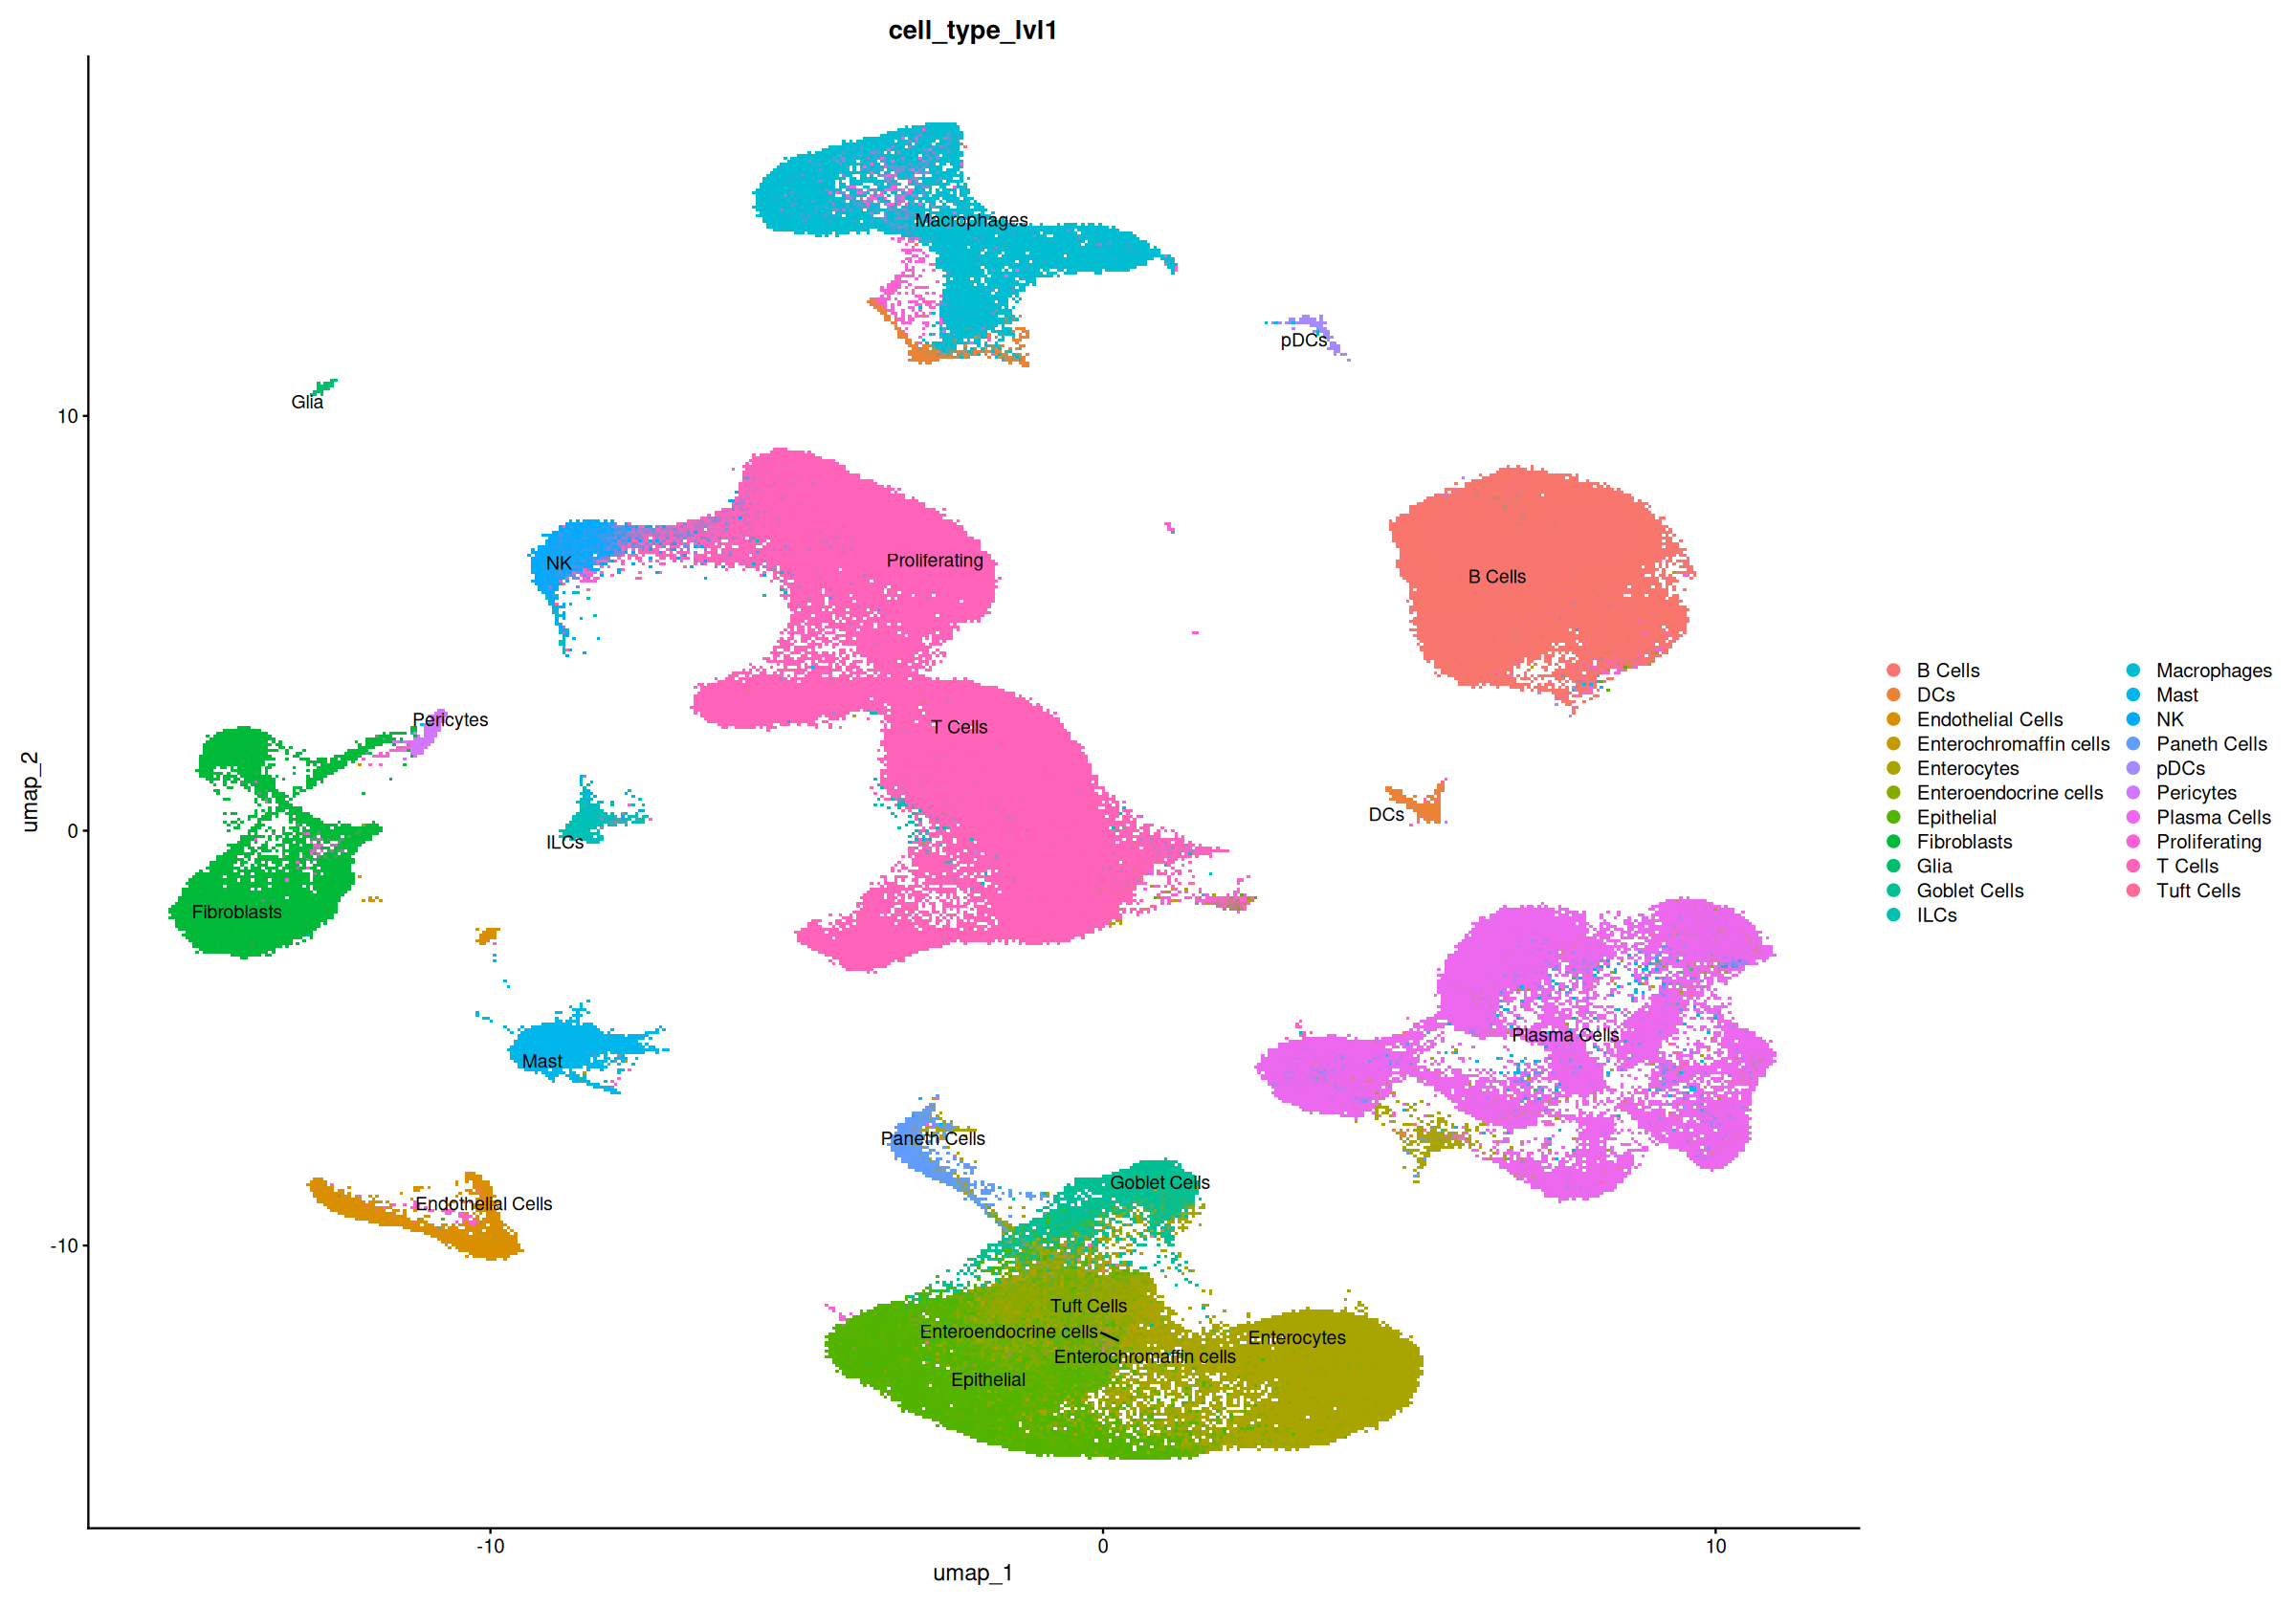

In [31]:
options(repr.plot.width = 20, repr.plot.height = 14)
DimPlot(ile_lps_5p_filt, group.by = "cell_type_lvl1", label = T, repel = T)

In [ ]:
ls()

In [20]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12040771,643.1,20015670,1069.0,20015670,1069.0
Vcells,2030567647,15492.1,9246498868,70545.2,11558030522,88180.8


In [19]:
rm(predict_3p)
rm(thomas_nichenet)

In [3]:
predict_3p  <- readRDS("data/old_predict/paper_final.rds")

In [7]:
predict_3p

An object of class Seurat 
22431 features across 197281 samples within 1 assay 
Active assay: RNA (22431 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [4]:
thomas_nichenet  <- readRDS("data/published_data/thomas/thomas_merged_subset_for_nichenet_2000.rds")

In [6]:
thomas_nichenet

An object of class Seurat 
34086 features across 163704 samples within 3 assays 
Active assay: RNA (33075 features, 1000 variable features)
 3 layers present: scale.data, data, counts
 2 other assays present: integrated, prediction.score.id

In [8]:
rm(list = ls())

In [7]:
ls()

[1] "ggtheme"       "ile_celltypes"

## Annotation of Cell types

In [6]:
ile_celltypes  <- readRDS("data/seu_ile_lp_filt.rds")

In [7]:
ile_celltypes@meta.data  %>% colnames

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [8]:
ile_celltypes

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [11]:
is.na(ile_celltypes$cell_type_lvl1)  %>% table

.
 FALSE 
672820 

In [14]:
is.na(ile_celltypes$cell_state)  %>% table

.
 FALSE 
672820 

In [ ]:
is.na(ile_celltypes$cell_type_lvl2)  %>% table

In [16]:
ile_celltypes@meta.data  %>% group_by(cell_type_lvl1, cell_type_lvl2, cellsubsets_plus_cd4_ctl)  %>% tally()

cell_type_lvl1,cell_type_lvl2,cellsubsets_plus_cd4_ctl,n
<chr>,<chr>,<chr>,<int>
B Cells,B Cells Memory,B Cells Memory,75250
B Cells,B Cells Naive,B Cells Naive,58355
DCs,DCs,DCs,5466
Endothelial Cells,ECs Arterial,ECs Arterial,705
Endothelial Cells,ECs Capillary,ECs Capillary,3678
Endothelial Cells,ECs Lymphatic,ECs Lymphatic,1295
Endothelial Cells,ECs Pericyte-like,ECs Pericyte-like,1291
Endothelial Cells,ECs Venous,ECs Venous,5251
Enterochromaffin cells,Enterochromaffin cells,Enterochromaffin cells,221


In [17]:
is.na(ile_celltypes$participant_id)  %>% table


.
 FALSE 
672820 

In [20]:
is.na(ile_celltypes$annotations)  %>% table


.
 FALSE   TRUE 
141520 531300 

In [19]:
colnames(ile_celltypes@meta.data )

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [23]:
ile_celltypes$prime  %>% table


.
    5p 
672820 

In [ ]:
ile_celltypes@meta.data  %>% group_by(cell_type_lvl1, cell_type_lvl2, cellsubsets_plus_cd4_ctl)  %>% tally()

In [9]:
DimPlot(ile_celltypes)

ERROR: [1m[33mError[39m in `DefaultDimReduc()`:[22m
[33m![39m Unable to find a DimReduc matching one of 'umap', 'tsne', or 'pca'; please specify a dimensional reduction to use
